# Задача 2. Источник света

Класс `Source` с выходом $Y = 10\,000$ фотонов/МэВ.

- **Число фотонов** линейно по энергии: $\langle n\rangle = Y E$. Фотоны излучаются независимо, поэтому $n$ разыгрывается по Пуассону (флаг `fluctuate=False` даёт ровно $\mathrm{round}(YE)$).
- **Изотропия**: $d\Omega = d\phi\, d\cos\theta$, поэтому $\phi \sim U(0, 2\pi)$, $\cos\theta \sim U(-1, 1)$. Направления — массив формы `(n, 3)`, как и координаты ФЭУ в `Detector`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from source import Source

src = Source(Y=10_000, rng=1)
d = src.directions(E=1.0)
print(d.shape)
print("нормы:", np.linalg.norm(d, axis=1)[:5])

(10003, 3)
нормы: [1. 1. 1. 1. 1.]


## Линейность выхода

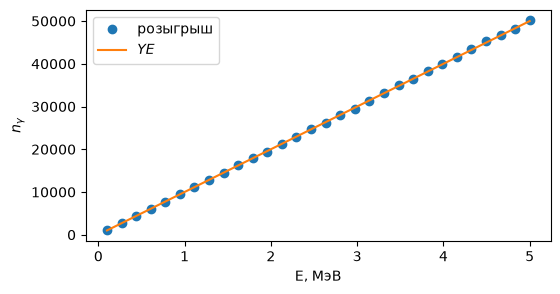

In [2]:
E = np.linspace(0.1, 5, 30)
n = np.array([src.n_photons(e) for e in E])
plt.figure(figsize=(6, 3))
plt.plot(E, n, 'o', label='розыгрыш')
plt.plot(E, src.Y*E, label='$YE$')
plt.xlabel('E, МэВ'); plt.ylabel(r'$n_\gamma$'); plt.legend(); plt.show()

## Пуассоновские флуктуации при E = 1 МэВ

<n> = 10000.7,  sigma = 98.4,  sqrt(YE) = 100.0


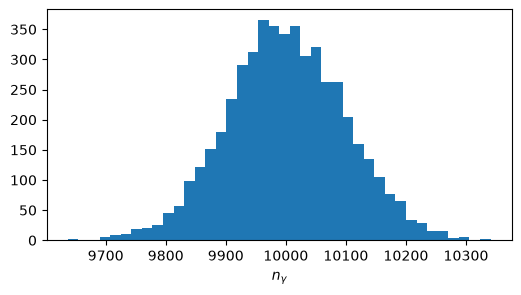

In [3]:
ns = np.array([src.n_photons(1.0) for _ in range(5000)])
print(f"<n> = {ns.mean():.1f},  sigma = {ns.std():.1f},  sqrt(YE) = {np.sqrt(src.Y):.1f}")
plt.figure(figsize=(6, 3)); plt.hist(ns, bins=40); plt.xlabel(r'$n_\gamma$'); plt.show()

## Проверка изотропии\nДля изотропного распределения $\cos\theta$ и $\phi$ равномерны, $\langle n_i\rangle = 0$, $\langle n_i^2\rangle = 1/3$.

<n>   = [ 0.0002 -0.0003 -0.0002]
<n^2> = [0.3334 0.3332 0.3334]


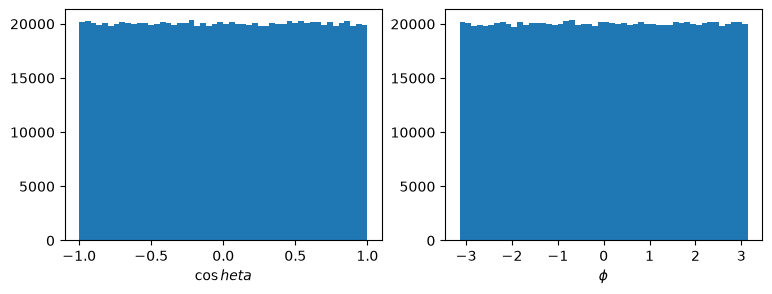

In [4]:
d = src.directions(E=100.0)   # ~1e6 фотонов
print("<n>   =", d.mean(axis=0).round(4))
print("<n^2> =", (d**2).mean(axis=0).round(4))
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(d[:, 2], bins=50); ax[0].set_xlabel(r'$\cos	heta$')
ax[1].hist(np.arctan2(d[:, 1], d[:, 0]), bins=50); ax[1].set_xlabel(r'$\phi$')
plt.show()

In [5]:
import k3d
plot = k3d.plot()
plot += k3d.vectors(np.zeros((300, 3), np.float32), src.directions(0.03)[:300].astype(np.float32), head_size=0.5)
plot.display()

Output()